<a href="https://colab.research.google.com/github/sanimp/Who-Gets-Flagged/blob/main/dropout_fairness_analysis_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Who Gets Flagged? Accuracy and Fairness of Early-Warning Models for Undergraduate Dropout

**Data:** UCI *Predict Students' Dropout and Academic Success* (id 697); Realinho et al. (2022), *Data*, 7(11).

**Research questions**
- **RQ1** How accurately can dropout be predicted at enrollment vs. after the 1st semester?
- **RQ2** Does gradient boosting (XGBoost) outperform logistic regression?
- **RQ3** Are predictions equally accurate and calibrated across gender, scholarship status, and age at enrollment?


## 0. Setup

In [ ]:
!pip install -q ucimlrepo xgboost shap statsmodels

from ucimlrepo import fetch_ucirepo

# fetch dataset
predict_students_dropout_and_academic_success = fetch_ucirepo(id=697)

# data (as pandas dataframes)
X = predict_students_dropout_and_academic_success.data.features
y = predict_students_dropout_and_academic_success.data.targets

# metadata and variable information
print(predict_students_dropout_and_academic_success.metadata)
print(predict_students_dropout_and_academic_success.variables)

# combine features + target and save, so the rest of the notebook can read it
data = X.join(y)
data.to_csv("data.csv", sep=";", index=False)
print("Saved data.csv:", data.shape)
print(data["Target"].value_counts())

{'uci_id': 697, 'name': "Predict Students' Dropout and Academic Success", 'repository_url': 'https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success', 'data_url': 'https://archive.ics.uci.edu/static/public/697/data.csv', 'abstract': "A dataset created from a higher education institution (acquired from several disjoint databases) related to students enrolled in different undergraduate degrees, such as agronomy, design, education, nursing, journalism, management, social service, and technologies.\nThe dataset includes information known at the time of student enrollment (academic path, demographics, and social-economic factors) and the students' academic performance at the end of the first and second semesters. \nThe data is used to build classification models to predict students' dropout and academic sucess. The problem is formulated as a three category classification task, in which there is a strong imbalance towards one of the classes.", 'area': 'Social Sc

# Part A — Descriptive statistics

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

OUT = "output"
os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

### 1. Load data

In [ ]:
def load_data():
    """Read data.csv (semicolon-separated)."""
    df = pd.read_csv("data.csv", sep=";")
    df.columns = df.columns.str.strip()  # some versions have stray tabs/spaces
    return df


def col(df, *keywords):
    """Find a column whose name contains all keywords (case-insensitive)."""
    hits = [c for c in df.columns if all(k.lower() in c.lower() for k in keywords)]
    if not hits:
        raise KeyError(f"No column matching {keywords}")
    return hits[0]


df = load_data()
print("\n=== DATA OVERVIEW ===")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Missing values (total): {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

# Key column names (robust to small naming differences)
TARGET = col(df, "target")
GENDER = col(df, "gender")
SCHOL = col(df, "scholarship")
AGE = col(df, "age")
DEBTOR = col(df, "debtor")
TUITION = col(df, "tuition")
DISPLACED = col(df, "displaced")
INTL = col(df, "international")
ADM = col(df, "admission grade")
PREVQ = col(df, "previous qualification", "grade")
SEM1_ENR = col(df, "1st sem", "enrolled")
SEM1_APP = col(df, "1st sem", "approved")
SEM1_GRD = col(df, "1st sem", "(grade)")
UNEMP = col(df, "unemployment")


=== DATA OVERVIEW ===
Rows: 4,424   Columns: 37
Missing values (total): 0
Duplicate rows: 0


### 2. Outcome distribution (full sample)

In [ ]:
counts = df[TARGET].value_counts()
t0 = pd.DataFrame({"n": counts, "percent": (100 * counts / len(df)).round(1)})
print("\n=== OUTCOME DISTRIBUTION (full sample) ===")
print(t0)
t0.to_csv(os.path.join(OUT, "table0_outcome_counts.csv"))


=== OUTCOME DISTRIBUTION (full sample) ===
             n  percent
Target                 
Graduate  2209     49.9
Dropout   1421     32.1
Enrolled   794     17.9


### 3. Analytic sample: Dropout vs Graduate (exclude still-Enrolled)

In [ ]:
ana = df[df[TARGET].isin(["Dropout", "Graduate"])].copy()
ana["dropout"] = (ana[TARGET] == "Dropout").astype(int)
print(f"\nAnalytic sample (Dropout + Graduate): {len(ana):,} "
      f"(excluded {len(df) - len(ana):,} still-enrolled students)")

# Readable group variables (coding per UCI documentation:
# Gender 1 = male, 0 = female; other binaries 1 = yes, 0 = no)
ana["Gender_lbl"] = ana[GENDER].map({1: "Male", 0: "Female"})
ana["Scholarship_lbl"] = ana[SCHOL].map({1: "Scholarship", 0: "No scholarship"})
ana["Age_group"] = pd.cut(ana[AGE], bins=[0, 20, 24, 200],
                          labels=["≤20", "21–24", "25+"])
ana["Debtor_lbl"] = ana[DEBTOR].map({1: "Debtor", 0: "Not debtor"})
ana["Tuition_lbl"] = ana[TUITION].map({1: "Fees up to date", 0: "Fees not up to date"})
ana["Displaced_lbl"] = ana[DISPLACED].map({1: "Displaced", 0: "Not displaced"})
ana["Intl_lbl"] = ana[INTL].map({1: "International", 0: "Domestic"})


Analytic sample (Dropout + Graduate): 3,630 (excluded 794 still-enrolled students)


### 4. Table 1: descriptives by outcome

In [ ]:
cont_vars = {
    "Age at enrollment": AGE,
    "Admission grade": ADM,
    "Previous qualification grade": PREVQ,
    "1st sem units enrolled": SEM1_ENR,
    "1st sem units approved": SEM1_APP,
    "1st sem average grade": SEM1_GRD,
    "Unemployment rate (%)": UNEMP,
}
bin_vars = {
    "Female": (GENDER, 0),
    "Scholarship holder": (SCHOL, 1),
    "Debtor": (DEBTOR, 1),
    "Tuition fees up to date": (TUITION, 1),
    "Displaced (lives away from home)": (DISPLACED, 1),
    "International student": (INTL, 1),
}

drop = ana[ana.dropout == 1]
grad = ana[ana.dropout == 0]
rows = []

for label, c in cont_vars.items():
    a, b, t = drop[c], grad[c], ana[c]
    pooled_sd = np.sqrt((a.var() + b.var()) / 2)
    smd = (a.mean() - b.mean()) / pooled_sd if pooled_sd > 0 else np.nan
    p = stats.mannwhitneyu(a, b).pvalue
    rows.append({
        "Variable": label,
        "Overall": f"{t.mean():.2f} ({t.std():.2f})",
        "Dropout": f"{a.mean():.2f} ({a.std():.2f})",
        "Graduate": f"{b.mean():.2f} ({b.std():.2f})",
        "SMD": round(smd, 2),
        "p": p,
        "Test": "Mann-Whitney U",
    })

for label, (c, val) in bin_vars.items():
    a = (drop[c] == val)
    b = (grad[c] == val)
    t = (ana[c] == val)
    p1, p2 = a.mean(), b.mean()
    pbar = (p1 + p2) / 2
    smd = (p1 - p2) / np.sqrt(pbar * (1 - pbar)) if 0 < pbar < 1 else np.nan
    p = stats.chi2_contingency(pd.crosstab(ana[c] == val, ana.dropout))[1]
    rows.append({
        "Variable": label + ", n (%)",
        "Overall": f"{t.sum()} ({100 * t.mean():.1f}%)",
        "Dropout": f"{a.sum()} ({100 * p1:.1f}%)",
        "Graduate": f"{b.sum()} ({100 * p2:.1f}%)",
        "SMD": round(smd, 2),
        "p": p,
        "Test": "Chi-square",
    })

t1 = pd.DataFrame(rows)
t1["p"] = t1["p"].apply(lambda x: "<.001" if x < .001 else f"{x:.3f}")
t1.columns = ["Variable", f"Overall (N={len(ana)})", f"Dropout (n={len(drop)})",
              f"Graduate (n={len(grad)})", "SMD", "p", "Test"]
print("\n=== TABLE 1: Characteristics by outcome — mean (SD) or n (%) ===")
print(t1.to_string(index=False))
t1.to_csv(os.path.join(OUT, "table1_descriptives.csv"), index=False)


=== TABLE 1: Characteristics by outcome — mean (SD) or n (%) ===
                               Variable Overall (N=3630) Dropout (n=1421) Graduate (n=2209)   SMD     p           Test
                      Age at enrollment     23.46 (7.83)     26.07 (8.70)      21.78 (6.69)  0.55 <.001 Mann-Whitney U
                        Admission grade   127.29 (14.61)   124.96 (15.13)    128.79 (14.07) -0.26 <.001 Mann-Whitney U
           Previous qualification grade   132.92 (13.24)   131.11 (12.87)    134.08 (13.34) -0.23 <.001 Mann-Whitney U
                 1st sem units enrolled      6.34 (2.57)      5.82 (2.33)       6.67 (2.66) -0.34 <.001 Mann-Whitney U
                 1st sem units approved      4.79 (3.24)      2.55 (2.86)       6.23 (2.58) -1.35 <.001 Mann-Whitney U
                  1st sem average grade     10.53 (5.06)      7.26 (6.03)      12.64 (2.70) -1.15 <.001 Mann-Whitney U
                  Unemployment rate (%)     11.63 (2.67)     11.62 (2.77)      11.64 (2.60) -0.01 0.6

### 5. Table 2: dropout rate by fairness-relevant groups, Wilson 95% CI

In [ ]:
group_vars = ["Gender_lbl", "Scholarship_lbl", "Age_group",
              "Debtor_lbl", "Tuition_lbl", "Displaced_lbl", "Intl_lbl"]
g_rows = []
for g in group_vars:
    for level, sub in ana.groupby(g, observed=True):
        k, n = sub.dropout.sum(), len(sub)
        lo, hi = proportion_confint(k, n, method="wilson")
        g_rows.append({"Grouping": g.replace("_lbl", "").replace("_", " "),
                       "Group": level, "n": n, "Dropouts": k,
                       "Dropout rate (%)": round(100 * k / n, 1),
                       "95% CI low": round(100 * lo, 1),
                       "95% CI high": round(100 * hi, 1)})
t2 = pd.DataFrame(g_rows)
print("\n=== TABLE 2: Dropout rate by group (Wilson 95% CI) ===")
print(t2.to_string(index=False))
t2.to_csv(os.path.join(OUT, "table2_dropout_by_group.csv"), index=False)


=== TABLE 2: Dropout rate by group (Wilson 95% CI) ===
   Grouping               Group    n  Dropouts  Dropout rate (%)  95% CI low  95% CI high
     Gender              Female 2381       720              30.2        28.4         32.1
     Gender                Male 1249       701              56.1        53.4         58.9
Scholarship      No scholarship 2661      1287              48.4        46.5         50.3
Scholarship         Scholarship  969       134              13.8        11.8         16.1
  Age group                 ≤20 2080       542              26.1        24.2         28.0
  Age group               21–24  574       248              43.2        39.2         47.3
  Age group                 25+  976       631              64.7        61.6         67.6
     Debtor              Debtor  413       312              75.5        71.2         79.4
     Debtor          Not debtor 3217      1109              34.5        32.9         36.1
    Tuition Fees not up to date  486       4

### 6. Figures

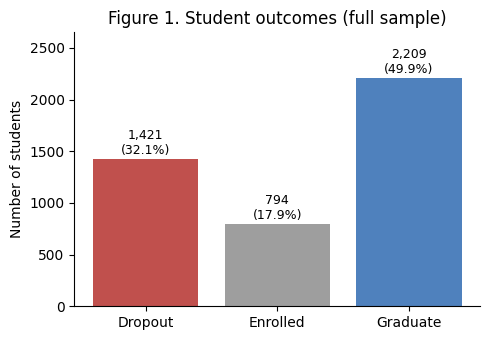

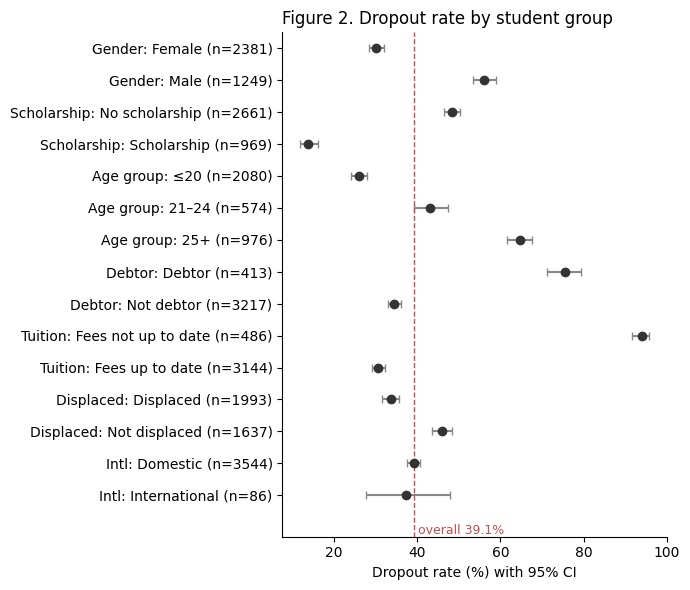

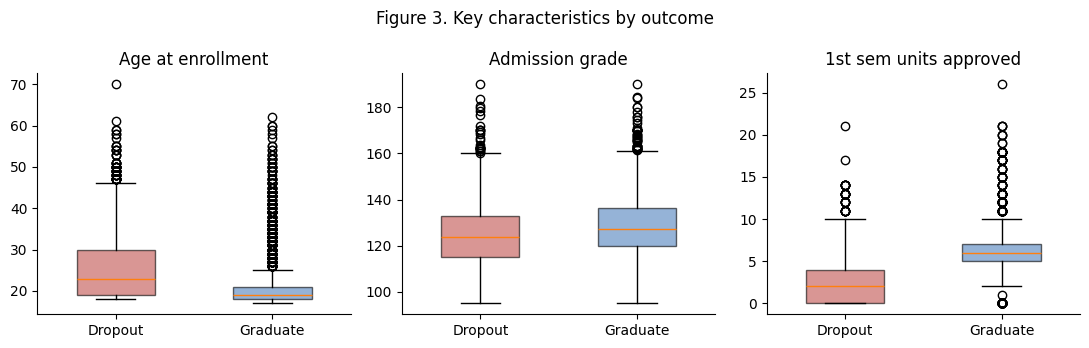


All tables and figures saved to ./output/


In [ ]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = {"Dropout": "#C0504D", "Enrolled": "#9E9E9E", "Graduate": "#4F81BD"}

# Fig 1: outcome distribution
fig, ax = plt.subplots(figsize=(5, 3.5))
order = ["Dropout", "Enrolled", "Graduate"]
vals = [counts.get(o, 0) for o in order]
bars = ax.bar(order, vals, color=[COLORS[o] for o in order])
for b_, v in zip(bars, vals):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 20,
            f"{v:,}\n({100 * v / len(df):.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Number of students")
ax.set_title("Figure 1. Student outcomes (full sample)")
ax.set_ylim(0, max(vals) * 1.2)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "fig1_outcome_distribution.png"), dpi=300)
plt.show()

# Fig 2: dropout rate by group with CIs
fig, ax = plt.subplots(figsize=(7, 6))
t2r = t2.iloc[::-1].reset_index(drop=True)
ypos = np.arange(len(t2r))
ax.errorbar(t2r["Dropout rate (%)"], ypos,
            xerr=[t2r["Dropout rate (%)"] - t2r["95% CI low"],
                  t2r["95% CI high"] - t2r["Dropout rate (%)"]],
            fmt="o", color="#333333", ecolor="#888888", capsize=3)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{r.Grouping}: {r.Group} (n={r.n})" for r in t2r.itertuples()])
overall = 100 * ana.dropout.mean()
ax.axvline(overall, ls="--", color=COLORS["Dropout"], lw=1)
ax.text(overall, -0.9, f" overall {overall:.1f}%", color=COLORS["Dropout"], fontsize=9, va="top")
ax.set_ylim(-1.3, len(t2r) - 0.5)
ax.set_xlabel("Dropout rate (%) with 95% CI")
ax.set_title("Figure 2. Dropout rate by student group", loc="left")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "fig2_dropout_by_group.png"), dpi=300)
plt.show()

# Fig 3: key continuous distributions by outcome
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, (lbl, c) in zip(axes, [("Age at enrollment", AGE),
                                ("Admission grade", ADM),
                                ("1st sem units approved", SEM1_APP)]):
    data = [drop[c], grad[c]]
    bp = ax.boxplot(data, patch_artist=True, widths=0.5)
    ax.set_xticks([1, 2], ["Dropout", "Graduate"])
    for patch, k in zip(bp["boxes"], ["Dropout", "Graduate"]):
        patch.set_facecolor(COLORS[k]); patch.set_alpha(0.6)
    ax.set_title(lbl)
fig.suptitle("Figure 3. Key characteristics by outcome")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "fig3_key_distributions.png"), dpi=300)
plt.show()

print(f"\nAll tables and figures saved to ./{OUT}/")

# Part B — Prediction models and fairness analysis

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss, roc_curve
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
N_BOOT = 1000          # bootstrap replications for CIs (lower to 200 for a quick run)
FLAG_RATE = 0.30       # institution can support the top 30% highest-risk students
OUT = "output_models"
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)

def rename_cols(d, mapping):
    """Rename columns ignoring case, spaces and tabs (UCI download vs CSV differ slightly)."""
    norm = lambda c: " ".join(str(c).split()).lower()
    m = {norm(k): v for k, v in mapping.items()}
    d = d.copy()
    d.columns = [m.get(norm(c), " ".join(str(c).split())) for c in d.columns]
    return d

### 1. Data

In [ ]:
df = pd.read_csv("data.csv", sep=";")
df.columns = df.columns.str.strip()
df = df[df["Target"].isin(["Dropout", "Graduate"])].copy()
df["dropout"] = (df["Target"] == "Dropout").astype(int)

# Readable names
df = rename_cols(df, {
    "Marital status": "marital", "Application mode": "app_mode",
    "Application order": "app_order", "Course": "course",
    "Daytime/evening attendance": "daytime", "Previous qualification": "prev_qual",
    "Previous qualification (grade)": "prev_grade", "Nacionality": "nationality",
    "Mother's qualification": "mother_qual", "Father's qualification": "father_qual",
    "Mother's occupation": "mother_occ", "Father's occupation": "father_occ",
    "Admission grade": "adm_grade", "Displaced": "displaced",
    "Educational special needs": "special_needs", "Debtor": "debtor",
    "Tuition fees up to date": "tuition_ok", "Gender": "male",
    "Scholarship holder": "scholarship", "Age at enrollment": "age",
    "International": "international",
    "Curricular units 1st sem (credited)": "s1_credited",
    "Curricular units 1st sem (enrolled)": "s1_enrolled",
    "Curricular units 1st sem (evaluations)": "s1_evals",
    "Curricular units 1st sem (approved)": "s1_approved",
    "Curricular units 1st sem (grade)": "s1_grade",
    "Curricular units 1st sem (without evaluations)": "s1_no_evals",
    "Unemployment rate": "unemployment", "Inflation rate": "inflation", "GDP": "gdp",
})
# Grade of 0 = no passing grade recorded (not a real score of zero)
df["s1_no_grade"] = (df["s1_grade"] == 0).astype(int)
df["s1_pass_rate"] = np.where(df["s1_enrolled"] > 0,
                              df["s1_approved"] / df["s1_enrolled"].replace(0, np.nan), 0)
df["s1_pass_rate"] = df["s1_pass_rate"].fillna(0)

# Fairness groups (evaluated, not just used as predictors)
df["Gender"] = np.where(df["male"] == 1, "Male", "Female")
df["Scholarship"] = np.where(df["scholarship"] == 1, "Scholarship", "No scholarship")
df["Age group"] = pd.cut(df["age"], [0, 20, 24, 200], labels=["≤20", "21–24", "25+"]).astype(str)
GROUPS = ["Gender", "Scholarship", "Age group"]

### 2. Feature sets

In [ ]:
CAT = ["marital", "app_mode", "course", "prev_qual", "nationality",
       "mother_qual", "father_qual", "mother_occ", "father_occ"]
NUM_ENROLL = ["app_order", "daytime", "prev_grade", "adm_grade", "displaced",
              "special_needs", "male", "scholarship", "age", "international",
              "unemployment", "inflation", "gdp"]
NUM_SEM1 = ["s1_credited", "s1_enrolled", "s1_evals", "s1_approved", "s1_grade",
            "s1_no_evals", "s1_no_grade", "s1_pass_rate"]
FINANCIAL = ["debtor", "tuition_ok"]

FEATURE_SETS = {
    "ENROLL": (CAT, NUM_ENROLL),
    "SEM1": (CAT, NUM_ENROLL + NUM_SEM1),
}

def preprocessor(cat, num):
    # rare categories (<20 students) are pooled into an 'infrequent' level
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=20, sparse_output=False), cat),
        ("num", StandardScaler(), num),
    ])

def make_models(cat, num):
    lr = Pipeline([("prep", preprocessor(cat, num)),
                   ("clf", LogisticRegression(max_iter=5000))])
    lr_grid = {"clf__C": [0.01, 0.1, 1, 10]}
    xgb = Pipeline([("prep", preprocessor(cat, num)),
                    ("clf", XGBClassifier(eval_metric="logloss", random_state=SEED,
                                          n_jobs=-1, verbosity=0))])
    xgb_grid = {"clf__n_estimators": [200, 400], "clf__max_depth": [2, 3, 4],
                "clf__learning_rate": [0.03, 0.1], "clf__subsample": [0.8, 1.0]}
    return {"Logistic regression": (lr, lr_grid), "XGBoost": (xgb, xgb_grid)}

### 3. Train / test split (stratified on outcome x gender so groups are represented)

In [ ]:
strat = df["dropout"].astype(str) + "_" + df["Gender"]
train, test = train_test_split(df, test_size=0.30, random_state=SEED, stratify=strat)
y_tr, y_te = train["dropout"].values, test["dropout"].values
print(f"Train n = {len(train)}, Test n = {len(test)}, test dropout rate = {y_te.mean():.3f}")
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

Train n = 2541, Test n = 1089, test dropout rate = 0.391


### 4. Metric helpers

In [ ]:
def calib_slope_intercept(y, p):
    """Calibration slope and intercept (logistic recalibration). Ideal: 1 and 0."""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    m = LogisticRegression(C=1e6, max_iter=1000).fit(logit, y)
    return m.coef_[0][0], m.intercept_[0]

def metrics(y, p, thr):
    flag = p >= thr
    out = {
        "n": len(y), "Base rate": y.mean(), "Mean predicted": p.mean(),
        "AUC": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        "Brier": brier_score_loss(y, p),
        "Flag rate": flag.mean(),
        "TPR (recall)": flag[y == 1].mean() if (y == 1).any() else np.nan,
        "FPR": flag[y == 0].mean() if (y == 0).any() else np.nan,
        "PPV (precision)": y[flag].mean() if flag.any() else np.nan,
    }
    out["Calib-in-the-large (pred − obs)"] = out["Mean predicted"] - out["Base rate"]
    return out

def boot_ci(y, p, fn, n=N_BOOT):
    vals = []
    idx = np.arange(len(y))
    for _ in range(n):
        b = rng.choice(idx, len(idx), replace=True)
        if len(np.unique(y[b])) < 2:
            continue
        vals.append(fn(y[b], p[b]))
    return np.percentile(vals, [2.5, 97.5])

### 5. Fit models for each window (RQ1, RQ2)

In [ ]:
fitted, preds, overall_rows, best_params = {}, {}, [], []
for window, (cat, num) in FEATURE_SETS.items():
    feats = cat + num
    for name, (pipe, grid) in make_models(cat, num).items():
        gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
        gs.fit(train[feats], y_tr)
        p = gs.predict_proba(test[feats])[:, 1]
        key = (window, name)
        fitted[key], preds[key] = gs.best_estimator_, p
        thr = np.quantile(p, 1 - FLAG_RATE)   # flag top 30% within this model
        m = metrics(y_te, p, thr)
        auc_lo, auc_hi = boot_ci(y_te, p, roc_auc_score)
        slope, intercept = calib_slope_intercept(y_te, p)
        overall_rows.append({
            "Window": window, "Model": name,
            "CV AUC (train)": round(gs.best_score_, 3),
            "Test AUC": round(m["AUC"], 3),
            "AUC 95% CI": f"[{auc_lo:.3f}, {auc_hi:.3f}]",
            "Brier": round(m["Brier"], 3),
            "Log loss": round(log_loss(y_te, p), 3),
            "Calib slope": round(slope, 2), "Calib intercept": round(intercept, 2),
            "TPR @top30%": round(m["TPR (recall)"], 3),
            "PPV @top30%": round(m["PPV (precision)"], 3),
        })
        best_params.append({"Window": window, "Model": name, **gs.best_params_})
        print(f"{window:6s} {name:20s} test AUC = {m['AUC']:.3f}")

t_overall = pd.DataFrame(overall_rows)
print("\n=== TABLE 3: Overall model performance (test set) ===")
print(t_overall.to_string(index=False))
t_overall.to_csv(os.path.join(OUT, "table3_overall_performance.csv"), index=False)
pd.DataFrame(best_params).to_csv(os.path.join(OUT, "best_hyperparameters.csv"), index=False)

# Paired bootstrap: is the XGBoost - LR difference in AUC real? (RQ2)
diff_rows = []
for window in FEATURE_SETS:
    p_lr, p_xgb = preds[(window, "Logistic regression")], preds[(window, "XGBoost")]
    d_obs = roc_auc_score(y_te, p_xgb) - roc_auc_score(y_te, p_lr)
    ds = []
    for _ in range(N_BOOT):
        b = rng.choice(len(y_te), len(y_te), replace=True)
        ds.append(roc_auc_score(y_te[b], p_xgb[b]) - roc_auc_score(y_te[b], p_lr[b]))
    lo, hi = np.percentile(ds, [2.5, 97.5])
    diff_rows.append({"Window": window, "AUC diff (XGB − LR)": round(d_obs, 3),
                      "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
# Gain from adding 1st-semester data
for name in ["Logistic regression", "XGBoost"]:
    a, b_ = preds[("ENROLL", name)], preds[("SEM1", name)]
    d_obs = roc_auc_score(y_te, b_) - roc_auc_score(y_te, a)
    ds = []
    for _ in range(N_BOOT):
        b = rng.choice(len(y_te), len(y_te), replace=True)
        ds.append(roc_auc_score(y_te[b], b_[b]) - roc_auc_score(y_te[b], a[b]))
    lo, hi = np.percentile(ds, [2.5, 97.5])
    diff_rows.append({"Window": f"SEM1 − ENROLL ({name})",
                      "AUC diff (XGB − LR)": round(d_obs, 3), "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
t_diff = pd.DataFrame(diff_rows).rename(columns={"AUC diff (XGB − LR)": "AUC difference"})
print("\n=== TABLE 4: Paired bootstrap AUC differences ===")
print(t_diff.to_string(index=False))
t_diff.to_csv(os.path.join(OUT, "table4_auc_differences.csv"), index=False)

ENROLL Logistic regression  test AUC = 0.819
ENROLL XGBoost              test AUC = 0.822
SEM1   Logistic regression  test AUC = 0.927
SEM1   XGBoost              test AUC = 0.929

=== TABLE 3: Overall model performance (test set) ===
Window               Model  CV AUC (train)  Test AUC     AUC 95% CI  Brier  Log loss  Calib slope  Calib intercept  TPR @top30%  PPV @top30%
ENROLL Logistic regression           0.794     0.819 [0.794, 0.845]  0.168     0.509         1.16             0.03        0.561        0.731
ENROLL             XGBoost           0.806     0.822 [0.798, 0.847]  0.166     0.503         1.07            -0.01        0.559        0.728
  SEM1 Logistic regression           0.925     0.927 [0.909, 0.945]  0.093     0.313         1.00             0.12        0.721        0.939
  SEM1             XGBoost           0.929     0.929 [0.912, 0.946]  0.089     0.301         1.04             0.01        0.728        0.948

=== TABLE 4: Paired bootstrap AUC differences ===
         

### 6. Fairness by group (RQ3)

In [ ]:
fair_rows = []
for (window, name), p in preds.items():
    thr = np.quantile(p, 1 - FLAG_RATE)
    for g in GROUPS:
        for level in sorted(test[g].unique()):
            mask = (test[g] == level).values
            m = metrics(y_te[mask], p[mask], thr)
            lo, hi = boot_ci(y_te[mask], p[mask], roc_auc_score, n=300)
            fair_rows.append({"Window": window, "Model": name, "Grouping": g,
                              "Group": level, **{k: round(v, 3) if isinstance(v, float) else v
                                                for k, v in m.items()},
                              "AUC 95% CI": f"[{lo:.3f}, {hi:.3f}]"})
t_fair = pd.DataFrame(fair_rows)
t_fair.to_csv(os.path.join(OUT, "table5_fairness_by_group.csv"), index=False)
print("\n=== TABLE 5 (excerpt): Fairness by group — XGBoost ===")
cols = ["Window", "Grouping", "Group", "n", "Base rate", "Mean predicted", "AUC",
        "Brier", "Flag rate", "TPR (recall)", "FPR", "PPV (precision)"]
print(t_fair[t_fair.Model == "XGBoost"][cols].to_string(index=False))

# Gaps between groups with bootstrap CIs (reference group listed first)
GAP_PAIRS = {"Gender": ("Male", "Female"),
             "Scholarship": ("No scholarship", "Scholarship"),
             "Age group": ("25+", "≤20")}

def gap_stats(y, p, g, a, b, thr):
    ma, mb = (g == a), (g == b)
    ra, rb = metrics(y[ma], p[ma], thr), metrics(y[mb], p[mb], thr)
    return {k: ra[k] - rb[k] for k in ["AUC", "TPR (recall)", "FPR", "Flag rate",
                                        "Calib-in-the-large (pred − obs)"]}

gap_rows = []
for (window, name), p in preds.items():
    thr = np.quantile(p, 1 - FLAG_RATE)
    for g, (a, b) in GAP_PAIRS.items():
        gv = test[g].values
        obs = gap_stats(y_te, p, gv, a, b, thr)
        boots = []
        for _ in range(N_BOOT):
            idx = rng.choice(len(y_te), len(y_te), replace=True)
            try:
                boots.append(gap_stats(y_te[idx], p[idx], gv[idx], a, b, thr))
            except ValueError:
                continue
        boots = pd.DataFrame(boots)
        for k, v in obs.items():
            lo, hi = np.nanpercentile(boots[k], [2.5, 97.5])
            gap_rows.append({"Window": window, "Model": name, "Comparison": f"{a} − {b}",
                             "Metric": k, "Gap": round(v, 3),
                             "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                             "CI excludes 0": not (lo <= 0 <= hi)})
t_gap = pd.DataFrame(gap_rows)
t_gap.to_csv(os.path.join(OUT, "table6_fairness_gaps.csv"), index=False)
print("\n=== TABLE 6 (excerpt): Group gaps — SEM1 XGBoost ===")
print(t_gap[(t_gap.Window == "SEM1") & (t_gap.Model == "XGBoost")].to_string(index=False))


=== TABLE 5 (excerpt): Fairness by group — XGBoost ===
Window    Grouping          Group   n  Base rate  Mean predicted   AUC  Brier  Flag rate  TPR (recall)   FPR  PPV (precision)
ENROLL      Gender         Female 714      0.303        0.317863 0.810  0.153      0.186         0.426 0.082            0.692
ENROLL      Gender           Male 375      0.560        0.545598 0.774  0.190      0.517         0.695 0.291            0.753
ENROLL Scholarship No scholarship 806      0.484        0.484172 0.780  0.191      0.401         0.600 0.214            0.724
ENROLL Scholarship    Scholarship 283      0.127        0.145973 0.721  0.094      0.014         0.111 0.000            1.000
ENROLL   Age group          21–24 187      0.444        0.438723 0.792  0.186      0.358         0.578 0.183            0.716
ENROLL   Age group            25+ 296      0.639        0.642767 0.748  0.189      0.689         0.804 0.486            0.745
ENROLL   Age group            ≤20 606      0.254        0.2627

### 7. Figures

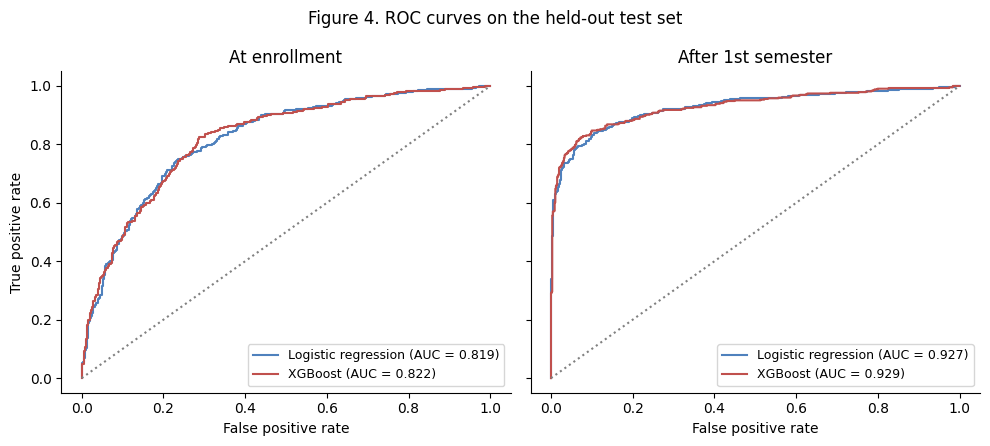

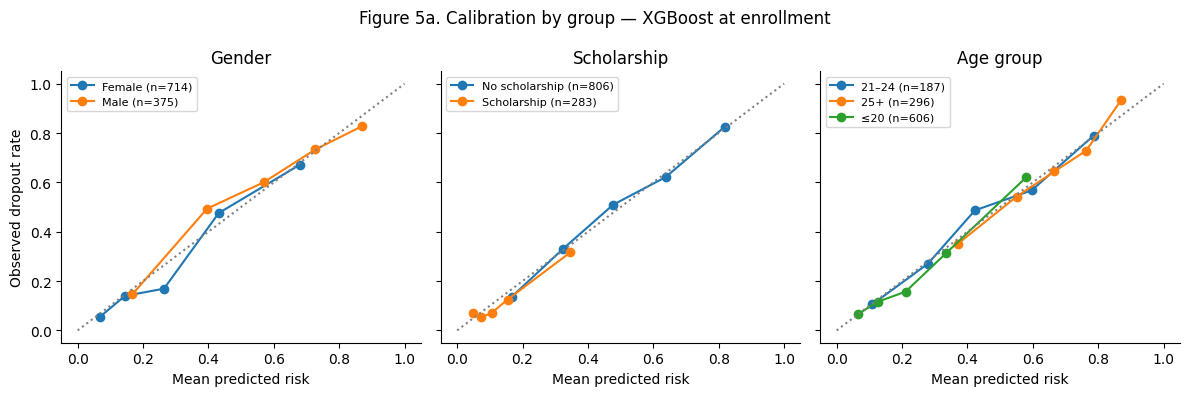

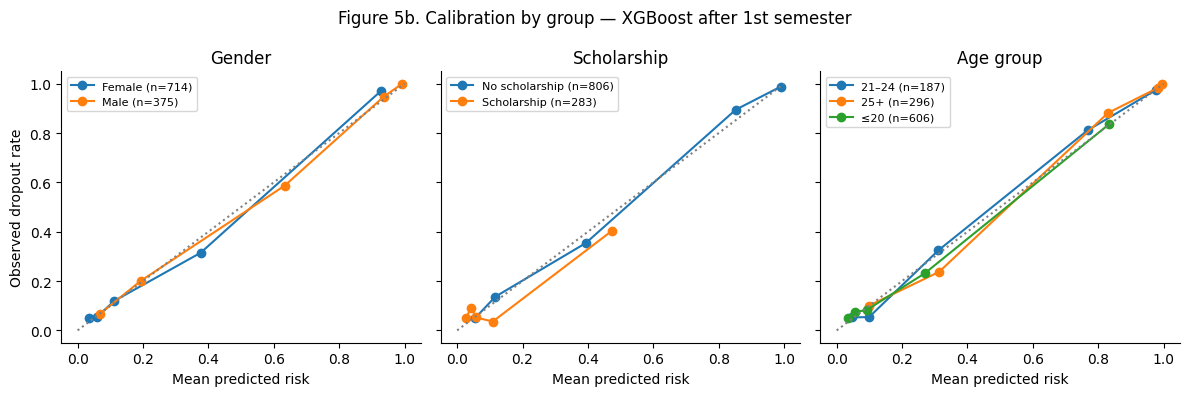

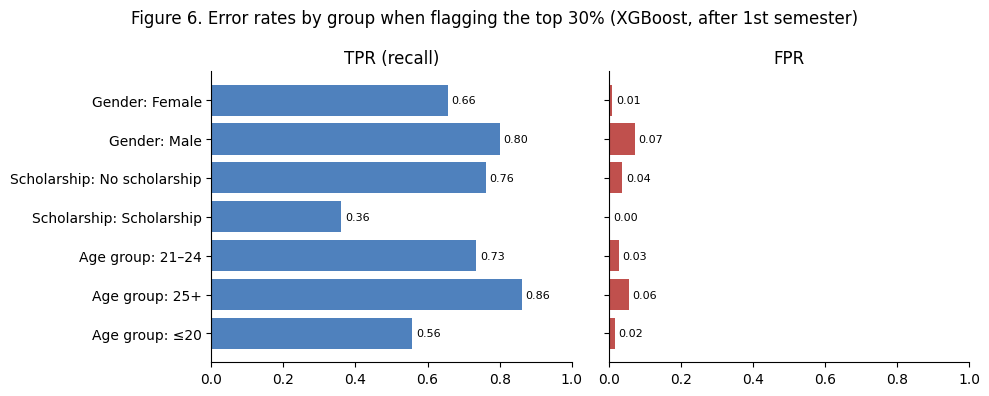

In [ ]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

# Fig 4: ROC curves
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, window in zip(axes, FEATURE_SETS):
    for name, c in [("Logistic regression", "#4F81BD"), ("XGBoost", "#C0504D")]:
        p = preds[(window, name)]
        fpr, tpr, _ = roc_curve(y_te, p)
        ax.plot(fpr, tpr, color=c, label=f"{name} (AUC = {roc_auc_score(y_te, p):.3f})")
    ax.plot([0, 1], [0, 1], ls=":", color="grey")
    ax.set_title({"ENROLL": "At enrollment", "SEM1": "After 1st semester"}[window])
    ax.set_xlabel("False positive rate"); ax.legend(loc="lower right", fontsize=9)
axes[0].set_ylabel("True positive rate")
fig.suptitle("Figure 4. ROC curves on the held-out test set")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig4_roc.png"), dpi=300); plt.show()

# Fig 5: calibration by group (SEM1 XGBoost and ENROLL XGBoost)
def calib_curve(y, p, bins=5):
    q = pd.qcut(p, bins, duplicates="drop")
    d = pd.DataFrame({"y": y, "p": p, "bin": q}).groupby("bin", observed=True)
    return d.p.mean().values, d.y.mean().values

for window in FEATURE_SETS:
    p = preds[(window, "XGBoost")]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
    for ax, g in zip(axes, GROUPS):
        for level in sorted(test[g].unique()):
            mask = (test[g] == level).values
            x, yy = calib_curve(y_te[mask], p[mask])
            ax.plot(x, yy, marker="o", label=f"{level} (n={mask.sum()})")
        ax.plot([0, 1], [0, 1], ls=":", color="grey")
        ax.set_title(g); ax.set_xlabel("Mean predicted risk"); ax.legend(fontsize=8)
    axes[0].set_ylabel("Observed dropout rate")
    label = {"ENROLL": "at enrollment", "SEM1": "after 1st semester"}[window]
    fig.suptitle(f"Figure 5{'a' if window == 'ENROLL' else 'b'}. "
                 f"Calibration by group — XGBoost {label}")
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, f"fig5_calibration_{window}.png"), dpi=300); plt.show()

# Fig 6: TPR / FPR by group at top-30% flagging (SEM1 XGBoost)
sub = t_fair[(t_fair.Window == "SEM1") & (t_fair.Model == "XGBoost")]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
labels = sub["Grouping"] + ": " + sub["Group"]
for ax, metric, c in [(axes[0], "TPR (recall)", "#4F81BD"), (axes[1], "FPR", "#C0504D")]:
    ax.barh(labels, sub[metric], color=c)
    ax.set_title(metric); ax.set_xlim(0, 1)
    for i, v in enumerate(sub[metric]):
        ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
axes[0].invert_yaxis()
fig.suptitle(f"Figure 6. Error rates by group when flagging the top {int(FLAG_RATE*100)}% "
             "(XGBoost, after 1st semester)")
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig6_error_rates.png"), dpi=300); plt.show()

### 8. SHAP — which features drive predictions (SEM1 XGBoost)


=== Top 10 SHAP features (ENROLL) ===
    feature  mean_abs_shap
        age       0.498744
scholarship       0.444220
       male       0.226881
course_9500       0.216136
  adm_grade       0.152636
 prev_grade       0.152053
 app_mode_1       0.135103
        gdp       0.089215
course_9119       0.083233
course_8014       0.069581


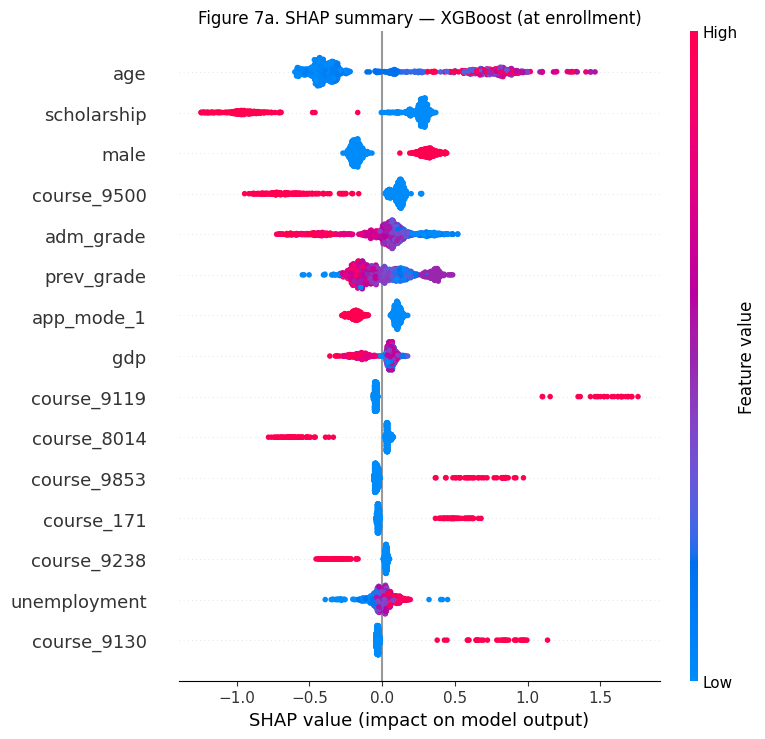


=== Top 10 SHAP features (SEM1) ===
     feature  mean_abs_shap
s1_pass_rate       1.509402
    s1_grade       0.341270
 s1_approved       0.328526
         age       0.324295
 scholarship       0.228400
  course_171       0.168303
 s1_credited       0.140649
   adm_grade       0.137018
unemployment       0.127169
        male       0.124470


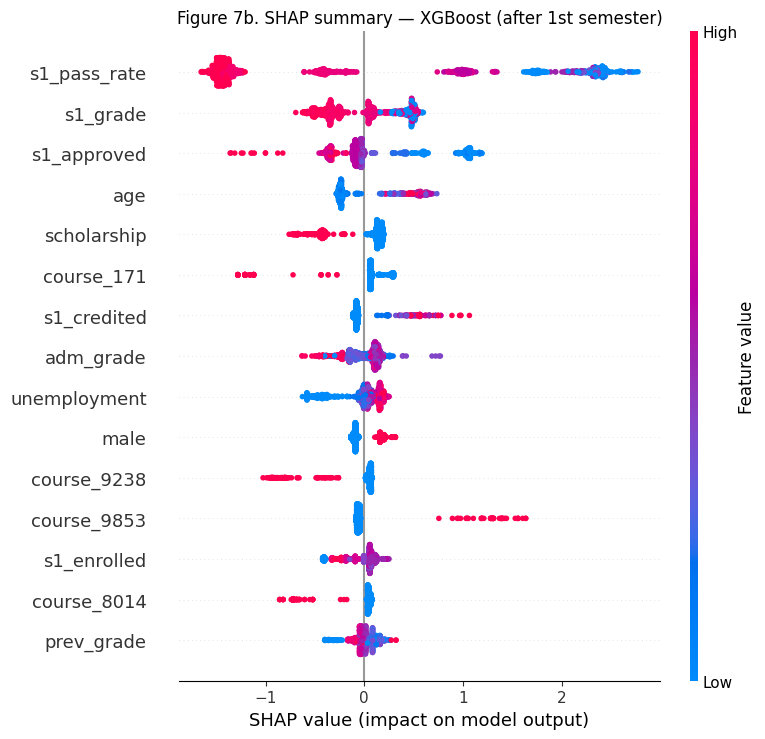

In [ ]:
try:
    import shap
    for window in FEATURE_SETS:
        pipe = fitted[(window, "XGBoost")]
        cat, num = FEATURE_SETS[window]
        Xt = pipe.named_steps["prep"].transform(test[cat + num])
        names = pipe.named_steps["prep"].get_feature_names_out()
        names = [n.split("__", 1)[1] for n in names]
        sv = shap.TreeExplainer(pipe.named_steps["clf"]).shap_values(Xt)
        imp = pd.DataFrame({"feature": names, "mean_abs_shap": np.abs(sv).mean(0)})
        imp = imp.sort_values("mean_abs_shap", ascending=False)
        imp.to_csv(os.path.join(OUT, f"table7_shap_importance_{window}.csv"), index=False)
        print(f"\n=== Top 10 SHAP features ({window}) ===")
        print(imp.head(10).to_string(index=False))
        plt.figure()
        shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
        plt.title(f"Figure 7{'a' if window == 'ENROLL' else 'b'}. SHAP summary — XGBoost "
                  f"({'at enrollment' if window == 'ENROLL' else 'after 1st semester'})")
        plt.tight_layout()
        plt.savefig(os.path.join(OUT, f"fig7_shap_{window}.png"), dpi=300, bbox_inches="tight")
        plt.show()
except ImportError:
    print("shap not installed — skipping SHAP (pip install shap)")

### 9. Robustness checks (XGBoost, fixed best hyperparameters)

In [ ]:
def refit_eval(window, cat, num, data_tr, data_te, label):
    base = fitted[(window, "XGBoost")]
    params = base.named_steps["clf"].get_params()
    pipe = Pipeline([("prep", preprocessor(cat, num)), ("clf", XGBClassifier(**params))])
    pipe.fit(data_tr[cat + num], data_tr["dropout"])
    p = pipe.predict_proba(data_te[cat + num])[:, 1]
    y = data_te["dropout"].values
    thr = np.quantile(p, 1 - FLAG_RATE)
    gv = data_te["Gender"].values
    g = gap_stats(y, p, gv, "Male", "Female", thr)
    return {"Check": label, "Window": window, "Test AUC": round(roc_auc_score(y, p), 3),
            "Brier": round(brier_score_loss(y, p), 3),
            "Male−Female TPR gap": round(g["TPR (recall)"], 3),
            "Male−Female FPR gap": round(g["FPR"], 3),
            "Male−Female flag-rate gap": round(g["Flag rate"], 3)}

rob = []
for window, (cat, num) in FEATURE_SETS.items():
    rob.append(refit_eval(window, cat, num, train, test, "Main model"))
    rob.append(refit_eval(window, cat, num + FINANCIAL, train, test,
                          "+ Debtor & tuition status"))
    rob.append(refit_eval(window, cat, [v for v in num if v != "male"], train, test,
                          "Gender removed from predictors"))

# Alternative outcome: Dropout vs (Graduate + Enrolled)
full = pd.read_csv("data.csv", sep=";"); full.columns = full.columns.str.strip()
full = rename_cols(full, dict(zip(
    ["Marital status", "Application mode", "Application order", "Course",
     "Daytime/evening attendance", "Previous qualification", "Previous qualification (grade)",
     "Nacionality", "Mother's qualification", "Father's qualification", "Mother's occupation",
     "Father's occupation", "Admission grade", "Displaced", "Educational special needs",
     "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder", "Age at enrollment",
     "International", "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
     "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
     "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
     "Unemployment rate", "Inflation rate", "GDP"],
    ["marital", "app_mode", "app_order", "course", "daytime", "prev_qual", "prev_grade",
     "nationality", "mother_qual", "father_qual", "mother_occ", "father_occ", "adm_grade",
     "displaced", "special_needs", "debtor", "tuition_ok", "male", "scholarship", "age",
     "international", "s1_credited", "s1_enrolled", "s1_evals", "s1_approved", "s1_grade",
     "s1_no_evals", "unemployment", "inflation", "gdp"])))
full["dropout"] = (full["Target"] == "Dropout").astype(int)
full["s1_no_grade"] = (full["s1_grade"] == 0).astype(int)
full["s1_pass_rate"] = (full["s1_approved"] / full["s1_enrolled"].replace(0, np.nan)).fillna(0)
full["Gender"] = np.where(full["male"] == 1, "Male", "Female")
f_tr, f_te = train_test_split(full, test_size=0.30, random_state=SEED,
                              stratify=full["dropout"].astype(str) + full["Gender"])
for window, (cat, num) in FEATURE_SETS.items():
    rob.append(refit_eval(window, cat, num, f_tr, f_te,
                          "Outcome: Dropout vs Graduate+Enrolled"))

t_rob = pd.DataFrame(rob)
print("\n=== TABLE 8: Robustness checks (XGBoost) ===")
print(t_rob.to_string(index=False))
t_rob.to_csv(os.path.join(OUT, "table8_robustness.csv"), index=False)

print(f"\nDone. All tables and figures saved to ./{OUT}/")


=== TABLE 8: Robustness checks (XGBoost) ===
                                Check Window  Test AUC  Brier  Male−Female TPR gap  Male−Female FPR gap  Male−Female flag-rate gap
                           Main model ENROLL     0.822  0.166                0.269                0.209                      0.331
            + Debtor & tuition status ENROLL     0.858  0.145                0.210                0.198                      0.319
       Gender removed from predictors ENROLL     0.815  0.169                0.156                0.124                      0.238
                           Main model   SEM1     0.929  0.089                0.143                0.063                      0.274
            + Debtor & tuition status   SEM1     0.934  0.082                0.124                0.018                      0.250
       Gender removed from predictors   SEM1     0.929  0.090                0.096                0.042                      0.246
Outcome: Dropout vs Graduate+Enrolled

## Download all outputs

In [ ]:
!zip -qr results.zip output output_models
try:
    from google.colab import files
    files.download("results.zip")
except Exception:
    print("Saved results.zip in the working folder")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>